# 07 — Mini benchmark and model-family screening

**Task:** regression — crop-yield prediction

This notebook performs a compact fixed-holdout screening of classical regression algorithms using
only the model-ready `TRAIN` and `VALIDATION` partitions generated by notebook 06.

The goals are to:

- compare different regression families;
- expose each family to a small number of manual hyperparameter configurations;
- inspect validation error and training–validation gaps;
- analyze residual behavior;
- select the **top three algorithm families** for formal hyperparameter optimization.

This notebook is intentionally **not** a grid search.

## Evaluation boundary

```text
TRAIN      -> fit candidate regressors
VALIDATION -> compare candidate regressors
TEST       -> protected and never loaded
```

The model-ready features were generated by a preparation workflow fitted only on TRAIN.

That frozen representation is appropriate for this fixed TRAIN/VALIDATION screen. During the later
cross-validated hyperparameter-optimization stage, preprocessing and feature selection must move back
inside each fold using `preparation_pipeline_template.joblib`.

In [1]:
from pathlib import Path
import json
import time
import warnings

import joblib
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, ElasticNet
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    HistGradientBoostingRegressor,
)
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    median_absolute_error,
    r2_score,
)

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
PASTEL_CMAP = sns.light_palette("#6C8EBF", as_cmap=True)
RANDOM_STATE = 42

In [2]:
def find_repo_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    for candidate in [start, *start.parents]:
        if (candidate / "data").exists() and (candidate / "notebooks").exists():
            return candidate
    raise FileNotFoundError("Repository root could not be located.")

ROOT = find_repo_root()
DATASET = "synthetic_crop_yield"
TASK_DIR = ROOT / "results" / DATASET / "model_screening"
FIG_DIR = TASK_DIR / "figures"
TABLE_DIR = TASK_DIR / "tables"

for path in [TASK_DIR, FIG_DIR, TABLE_DIR]:
    path.mkdir(parents=True, exist_ok=True)

TRAIN_PATH = ROOT / "data" / DATASET / "ml_ready" / "train_ready.csv"
VALIDATION_PATH = ROOT / "data" / DATASET / "ml_ready" / "validation_ready.csv"
MANIFEST_PATH = ROOT / "results" / DATASET / "ml_preparation" / "preparation_manifest.json"
FITTED_PREPARATION_PATH = ROOT / "results" / DATASET / "ml_preparation" / "artifacts" / "preparation_pipeline_fitted.joblib"
TEMPLATE_PREPARATION_PATH = ROOT / "results" / DATASET / "ml_preparation" / "artifacts" / "preparation_pipeline_template.joblib"

for required in [
    TRAIN_PATH,
    VALIDATION_PATH,
    MANIFEST_PATH,
    FITTED_PREPARATION_PATH,
    TEMPLATE_PREPARATION_PATH,
]:
    if not required.exists():
        raise FileNotFoundError(
            f"Missing required artifact: {required}\n"
            "Run notebook 06_end_to_end_ml_preparation.ipynb first."
        )

print("Repository:", ROOT)
print("TRAIN:", TRAIN_PATH.relative_to(ROOT))
print("VALIDATION:", VALIDATION_PATH.relative_to(ROOT))
print("TEST is intentionally not loaded in this notebook.")

Repository: /home/david/Desktop/depto_computacion/ml_2026/demos_machine_learning_2026
TRAIN: data/synthetic_crop_yield/ml_ready/train_ready.csv
VALIDATION: data/synthetic_crop_yield/ml_ready/validation_ready.csv
TEST is intentionally not loaded in this notebook.


In [3]:
with MANIFEST_PATH.open("r", encoding="utf-8") as handle:
    manifest = json.load(handle)

fitted_preparation = joblib.load(FITTED_PREPARATION_PATH)
preparation_template = joblib.load(TEMPLATE_PREPARATION_PATH)

train_df = pd.read_csv(TRAIN_PATH)
val_df = pd.read_csv(VALIDATION_PATH)

ID_COL = manifest["identifier"]
TARGET = manifest["target"]
SELECTED_FEATURES = manifest["selected_features"]

expected_columns = [ID_COL, *SELECTED_FEATURES, TARGET]
assert not (set(expected_columns) - set(train_df.columns))
assert not (set(expected_columns) - set(val_df.columns))

X_train = train_df[SELECTED_FEATURES].copy()
y_train = train_df[TARGET].astype(float).copy()
X_val = val_df[SELECTED_FEATURES].copy()
y_val = val_df[TARGET].astype(float).copy()

print(f"TRAIN:      X={X_train.shape}, y={y_train.shape}")
print(f"VALIDATION: X={X_val.shape}, y={y_val.shape}")
print(f"Target units: t/ha")

TRAIN:      X=(840, 17), y=(840,)
VALIDATION: X=(180, 17), y=(180,)
Target units: t/ha


In [4]:
target_summary = pd.DataFrame(
    {
        "partition": ["TRAIN", "VALIDATION"],
        "n": [len(y_train), len(y_val)],
        "mean": [y_train.mean(), y_val.mean()],
        "std": [y_train.std(), y_val.std()],
        "median": [y_train.median(), y_val.median()],
        "q10": [y_train.quantile(0.10), y_val.quantile(0.10)],
        "q90": [y_train.quantile(0.90), y_val.quantile(0.90)],
    }
)
target_summary

,partition,n,mean,std,median,q10,q90
0,TRAIN,840,4.232071,1.49868,4.34,2.210,6.081
1,VALIDATION,180,4.357333,1.43645,4.55,2.355,5.990


## Candidate registry

The screen spans several inductive biases:

- unregularized linear regression;
- Ridge;
- Elastic Net;
- K-nearest-neighbor regression;
- support-vector regression;
- Random Forest;
- Extra Trees;
- histogram-based gradient boosting.

A mean `DummyRegressor` provides a reference baseline and cannot be selected for optimization.

In [5]:
candidate_specs = [
    {
        "family": "Baseline",
        "config_id": "dummy_mean",
        "is_baseline": True,
        "estimator": DummyRegressor(strategy="mean"),
        "params": {"strategy": "mean"},
    },

    {
        "family": "Linear Regression",
        "config_id": "linear_default",
        "is_baseline": False,
        "estimator": LinearRegression(),
        "params": {},
    },

    {
        "family": "Ridge",
        "config_id": "ridge_alpha0.1",
        "is_baseline": False,
        "estimator": Ridge(alpha=0.1),
        "params": {"alpha": 0.1},
    },
    {
        "family": "Ridge",
        "config_id": "ridge_alpha1",
        "is_baseline": False,
        "estimator": Ridge(alpha=1.0),
        "params": {"alpha": 1.0},
    },
    {
        "family": "Ridge",
        "config_id": "ridge_alpha10",
        "is_baseline": False,
        "estimator": Ridge(alpha=10.0),
        "params": {"alpha": 10.0},
    },

    {
        "family": "Elastic Net",
        "config_id": "enet_a0.001_l10.2",
        "is_baseline": False,
        "estimator": ElasticNet(alpha=0.001, l1_ratio=0.2, max_iter=10000, random_state=RANDOM_STATE),
        "params": {"alpha": 0.001, "l1_ratio": 0.2},
    },
    {
        "family": "Elastic Net",
        "config_id": "enet_a0.01_l10.5",
        "is_baseline": False,
        "estimator": ElasticNet(alpha=0.01, l1_ratio=0.5, max_iter=10000, random_state=RANDOM_STATE),
        "params": {"alpha": 0.01, "l1_ratio": 0.5},
    },
    {
        "family": "Elastic Net",
        "config_id": "enet_a0.05_l10.8",
        "is_baseline": False,
        "estimator": ElasticNet(alpha=0.05, l1_ratio=0.8, max_iter=10000, random_state=RANDOM_STATE),
        "params": {"alpha": 0.05, "l1_ratio": 0.8},
    },

    {
        "family": "KNN",
        "config_id": "knn_k5_uniform",
        "is_baseline": False,
        "estimator": KNeighborsRegressor(n_neighbors=5, weights="uniform"),
        "params": {"n_neighbors": 5, "weights": "uniform"},
    },
    {
        "family": "KNN",
        "config_id": "knn_k15_distance",
        "is_baseline": False,
        "estimator": KNeighborsRegressor(n_neighbors=15, weights="distance"),
        "params": {"n_neighbors": 15, "weights": "distance"},
    },
    {
        "family": "KNN",
        "config_id": "knn_k25_uniform",
        "is_baseline": False,
        "estimator": KNeighborsRegressor(n_neighbors=25, weights="uniform"),
        "params": {"n_neighbors": 25, "weights": "uniform"},
    },

    {
        "family": "SVR",
        "config_id": "svr_linear_C1",
        "is_baseline": False,
        "estimator": SVR(kernel="linear", C=1.0, epsilon=0.1),
        "params": {"kernel": "linear", "C": 1.0, "epsilon": 0.1},
    },
    {
        "family": "SVR",
        "config_id": "svr_rbf_C1",
        "is_baseline": False,
        "estimator": SVR(kernel="rbf", C=1.0, epsilon=0.1, gamma="scale"),
        "params": {"kernel": "rbf", "C": 1.0, "epsilon": 0.1, "gamma": "scale"},
    },
    {
        "family": "SVR",
        "config_id": "svr_rbf_C10",
        "is_baseline": False,
        "estimator": SVR(kernel="rbf", C=10.0, epsilon=0.2, gamma="scale"),
        "params": {"kernel": "rbf", "C": 10.0, "epsilon": 0.2, "gamma": "scale"},
    },

    {
        "family": "Random Forest",
        "config_id": "rf_default",
        "is_baseline": False,
        "estimator": RandomForestRegressor(
            n_estimators=300,
            max_depth=None,
            min_samples_leaf=1,
            random_state=RANDOM_STATE,
            n_jobs=-1,
        ),
        "params": {"n_estimators": 300, "max_depth": None, "min_samples_leaf": 1},
    },
    {
        "family": "Random Forest",
        "config_id": "rf_depth10_leaf2",
        "is_baseline": False,
        "estimator": RandomForestRegressor(
            n_estimators=300,
            max_depth=10,
            min_samples_leaf=2,
            random_state=RANDOM_STATE,
            n_jobs=-1,
        ),
        "params": {"n_estimators": 300, "max_depth": 10, "min_samples_leaf": 2},
    },
    {
        "family": "Random Forest",
        "config_id": "rf_depth6_leaf4",
        "is_baseline": False,
        "estimator": RandomForestRegressor(
            n_estimators=300,
            max_depth=6,
            min_samples_leaf=4,
            random_state=RANDOM_STATE,
            n_jobs=-1,
        ),
        "params": {"n_estimators": 300, "max_depth": 6, "min_samples_leaf": 4},
    },

    {
        "family": "Extra Trees",
        "config_id": "et_default",
        "is_baseline": False,
        "estimator": ExtraTreesRegressor(
            n_estimators=300,
            max_depth=None,
            min_samples_leaf=1,
            random_state=RANDOM_STATE,
            n_jobs=-1,
        ),
        "params": {"n_estimators": 300, "max_depth": None, "min_samples_leaf": 1},
    },
    {
        "family": "Extra Trees",
        "config_id": "et_depth10_leaf2",
        "is_baseline": False,
        "estimator": ExtraTreesRegressor(
            n_estimators=300,
            max_depth=10,
            min_samples_leaf=2,
            random_state=RANDOM_STATE,
            n_jobs=-1,
        ),
        "params": {"n_estimators": 300, "max_depth": 10, "min_samples_leaf": 2},
    },
    {
        "family": "Extra Trees",
        "config_id": "et_depth6_leaf4",
        "is_baseline": False,
        "estimator": ExtraTreesRegressor(
            n_estimators=300,
            max_depth=6,
            min_samples_leaf=4,
            random_state=RANDOM_STATE,
            n_jobs=-1,
        ),
        "params": {"n_estimators": 300, "max_depth": 6, "min_samples_leaf": 4},
    },

    {
        "family": "HistGradientBoosting",
        "config_id": "hgb_lr0.05_leaf15",
        "is_baseline": False,
        "estimator": HistGradientBoostingRegressor(
            learning_rate=0.05,
            max_iter=200,
            max_leaf_nodes=15,
            l2_regularization=0.0,
            random_state=RANDOM_STATE,
        ),
        "params": {"learning_rate": 0.05, "max_iter": 200, "max_leaf_nodes": 15, "l2_regularization": 0.0},
    },
    {
        "family": "HistGradientBoosting",
        "config_id": "hgb_lr0.10_leaf31",
        "is_baseline": False,
        "estimator": HistGradientBoostingRegressor(
            learning_rate=0.10,
            max_iter=200,
            max_leaf_nodes=31,
            l2_regularization=0.0,
            random_state=RANDOM_STATE,
        ),
        "params": {"learning_rate": 0.10, "max_iter": 200, "max_leaf_nodes": 31, "l2_regularization": 0.0},
    },
    {
        "family": "HistGradientBoosting",
        "config_id": "hgb_lr0.05_leaf31_l2",
        "is_baseline": False,
        "estimator": HistGradientBoostingRegressor(
            learning_rate=0.05,
            max_iter=250,
            max_leaf_nodes=31,
            l2_regularization=1.0,
            random_state=RANDOM_STATE,
        ),
        "params": {"learning_rate": 0.05, "max_iter": 250, "max_leaf_nodes": 31, "l2_regularization": 1.0},
    },
]

pd.DataFrame(
    [
        {
            "family": item["family"],
            "config_id": item["config_id"],
            "is_baseline": item["is_baseline"],
            "params": json.dumps(item["params"], sort_keys=True),
        }
        for item in candidate_specs
    ]
)

,family,config_id,is_baseline,params
0,Baseline,dummy_mean,True,"{""strategy"": ""mean""}"
1,Linear Regression,linear_default,False,{}
2,Ridge,ridge_alpha0.1,False,"{""alpha"": 0.1}"
3,Ridge,ridge_alpha1,False,"{""alpha"": 1.0}"
4,Ridge,ridge_alpha10,False,"{""alpha"": 10.0}"
5,Elastic Net,enet_a0.001_l10.2,False,"{""alpha"": 0.001, ""l1_ratio"": 0.2}"
6,Elastic Net,enet_a0.01_l10.5,False,"{""alpha"": 0.01, ""l1_ratio"": 0.5}"
7,Elastic Net,enet_a0.05_l10.8,False,"{""alpha"": 0.05, ""l1_ratio"": 0.8}"
8,KNN,knn_k5_uniform,False,"{""n_neighbors"": 5, ""weights"": ""uniform""}"
9,KNN,knn_k15_distance,False,"{""n_neighbors"": 15, ""weights"": ""distance""}"


## Metrics and screening rule

The primary metric is **validation MAE**, expressed directly in `t/ha`.

Secondary metrics:

- RMSE;
- median absolute error;
- $R^2$.

Lower MAE and RMSE are better. Higher $R^2$ is better.

Within each family we retain the manual configuration with the smallest validation MAE, then rank
families by validation MAE, validation RMSE, and $R^2$. TRAIN errors are used to diagnose possible
overfitting but do not determine the winner.

In [6]:
def regression_metrics(y_true, y_pred):
    return {
        "mae": mean_absolute_error(y_true, y_pred),
        "rmse": np.sqrt(mean_squared_error(y_true, y_pred)),
        "median_ae": median_absolute_error(y_true, y_pred),
        "r2": r2_score(y_true, y_pred),
    }

results = []
fitted_by_config = {}

for spec in candidate_specs:
    model = clone(spec["estimator"])

    start = time.perf_counter()
    model.fit(X_train, y_train)
    fit_seconds = time.perf_counter() - start

    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)

    train_metrics = regression_metrics(y_train, train_pred)
    val_metrics = regression_metrics(y_val, val_pred)

    row = {
        "family": spec["family"],
        "config_id": spec["config_id"],
        "is_baseline": spec["is_baseline"],
        "params": json.dumps(spec["params"], sort_keys=True),
        "fit_seconds": fit_seconds,
    }
    row.update({f"train_{k}": v for k, v in train_metrics.items()})
    row.update({f"val_{k}": v for k, v in val_metrics.items()})
    row["mae_gap_val_minus_train"] = row["val_mae"] - row["train_mae"]
    results.append(row)
    fitted_by_config[spec["config_id"]] = model

results_df = pd.DataFrame(results).sort_values(
    ["val_mae", "val_rmse", "val_r2"],
    ascending=[True, True, False],
).reset_index(drop=True)

results_df.to_csv(TABLE_DIR / "candidate_results.csv", index=False)
results_df.head(12)

,family,config_id,is_baseline,params,fit_seconds,train_mae,train_rmse,train_median_ae,train_r2,val_mae,val_rmse,val_median_ae,val_r2,mae_gap_val_minus_train
0,Linear Regression,linear_default,False,{},0.003295,0.799246,1.028686,0.647454,0.528301,0.840810,1.060297,0.700881,0.452110,0.041563
1,Ridge,ridge_alpha0.1,False,"{""alpha"": 0.1}",0.002515,0.799263,1.028711,0.644936,0.528278,0.841264,1.060588,0.698770,0.451808,0.042001
2,SVR,svr_rbf_C1,False,"{""C"": 1.0, ""epsilon"": 0.1, ""gamma"": ""scale"", ""...",0.032527,0.627684,0.890507,0.424448,0.646512,0.841608,1.071350,0.658469,0.440627,0.213924
3,Elastic Net,enet_a0.001_l10.2,False,"{""alpha"": 0.001, ""l1_ratio"": 0.2}",0.006654,0.800510,1.029813,0.646509,0.527266,0.844528,1.062869,0.701098,0.449448,0.044018
4,Ridge,ridge_alpha1,False,"{""alpha"": 1.0}",0.002783,0.801500,1.030744,0.646260,0.526412,0.846522,1.064275,0.706623,0.447990,0.045022
5,SVR,svr_linear_C1,False,"{""C"": 1.0, ""epsilon"": 0.1, ""kernel"": ""linear""}",0.066681,0.794221,1.039624,0.631123,0.518216,0.857154,1.090314,0.695843,0.420649,0.062933
6,Elastic Net,enet_a0.01_l10.5,False,"{""alpha"": 0.01, ""l1_ratio"": 0.5}",0.003210,0.829638,1.059284,0.665779,0.499823,0.873269,1.090472,0.762588,0.420481,0.043631
7,HistGradientBoosting,hgb_lr0.05_leaf15,False,"{""l2_regularization"": 0.0, ""learning_rate"": 0....",0.189603,0.396804,0.504834,0.324484,0.886395,0.884226,1.130975,0.788868,0.376631,0.487422
8,Random Forest,rf_depth10_leaf2,False,"{""max_depth"": 10, ""min_samples_leaf"": 2, ""n_es...",0.320068,0.473851,0.600653,0.397965,0.839177,0.886731,1.122764,0.728925,0.385651,0.412881
9,Ridge,ridge_alpha10,False,"{""alpha"": 10.0}",0.002034,0.847182,1.079515,0.678566,0.480535,0.890002,1.109381,0.799602,0.400208,0.042820


## Performance exploration

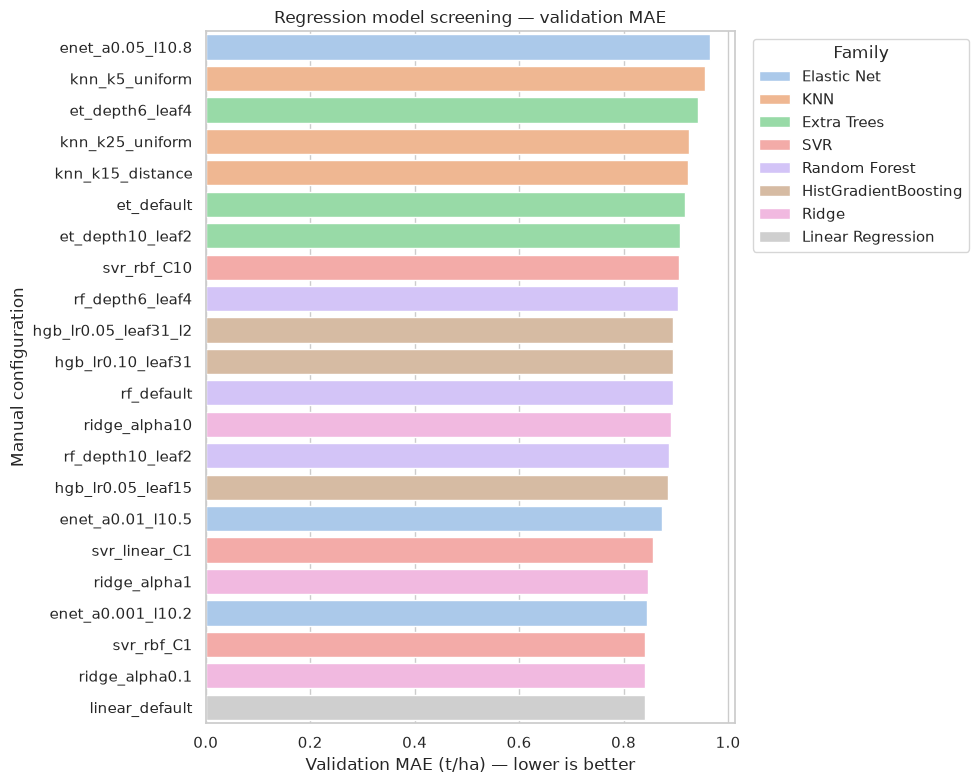

In [7]:
plot_df = results_df.loc[~results_df["is_baseline"]].sort_values("val_mae", ascending=False)

plt.figure(figsize=(10, 8))
sns.barplot(data=plot_df, x="val_mae", y="config_id", hue="family", dodge=False, palette="pastel")
plt.xlabel("Validation MAE (t/ha) — lower is better")
plt.ylabel("Manual configuration")
plt.title("Regression model screening — validation MAE")
plt.legend(title="Family", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(FIG_DIR / "01_candidate_validation_mae.png", dpi=160, bbox_inches="tight")
plt.show()

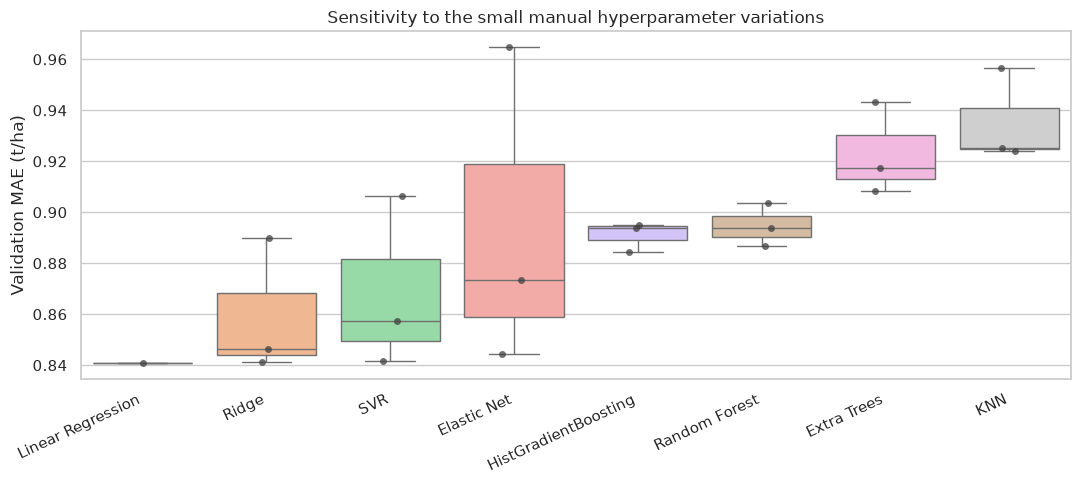

In [8]:
plt.figure(figsize=(11, 5))
sns.boxplot(
    data=results_df.loc[~results_df["is_baseline"]],
    x="family",
    y="val_mae",
    palette="pastel",
    showfliers=False,
)
sns.stripplot(
    data=results_df.loc[~results_df["is_baseline"]],
    x="family",
    y="val_mae",
    color="0.25",
    size=5,
    alpha=0.75,
)
plt.xticks(rotation=25, ha="right")
plt.ylabel("Validation MAE (t/ha)")
plt.xlabel("")
plt.title("Sensitivity to the small manual hyperparameter variations")
plt.tight_layout()
plt.savefig(FIG_DIR / "02_family_validation_mae_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

In [9]:
nonbaseline = results_df.loc[~results_df["is_baseline"]].copy()
family_best = (
    nonbaseline.sort_values(
        ["val_mae", "val_rmse", "val_r2", "mae_gap_val_minus_train"],
        ascending=[True, True, False, True],
    )
    .groupby("family", as_index=False, sort=False)
    .first()
)
family_best = family_best.sort_values(
    ["val_mae", "val_rmse", "val_r2", "mae_gap_val_minus_train"],
    ascending=[True, True, False, True],
).reset_index(drop=True)
family_best["family_rank"] = np.arange(1, len(family_best) + 1)

family_best.to_csv(TABLE_DIR / "family_best_results.csv", index=False)
family_best[
    [
        "family_rank",
        "family",
        "config_id",
        "val_mae",
        "val_rmse",
        "val_median_ae",
        "val_r2",
        "mae_gap_val_minus_train",
    ]
]

,family_rank,family,config_id,val_mae,val_rmse,val_median_ae,val_r2,mae_gap_val_minus_train
0,1,Linear Regression,linear_default,0.840810,1.060297,0.700881,0.452110,0.041563
1,2,Ridge,ridge_alpha0.1,0.841264,1.060588,0.698770,0.451808,0.042001
2,3,SVR,svr_rbf_C1,0.841608,1.071350,0.658469,0.440627,0.213924
3,4,Elastic Net,enet_a0.001_l10.2,0.844528,1.062869,0.701098,0.449448,0.044018
4,5,HistGradientBoosting,hgb_lr0.05_leaf15,0.884226,1.130975,0.788868,0.376631,0.487422
5,6,Random Forest,rf_depth10_leaf2,0.886731,1.122764,0.728925,0.385651,0.412881
6,7,Extra Trees,et_depth10_leaf2,0.908398,1.148251,0.811416,0.357442,0.451309
7,8,KNN,knn_k15_distance,0.924069,1.170512,0.763715,0.332286,0.924069


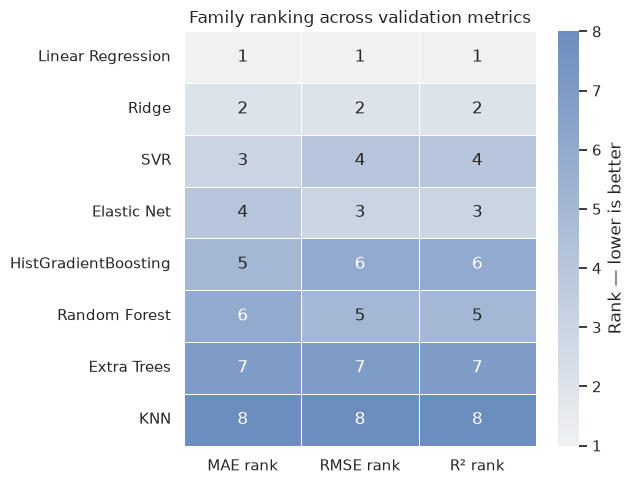

In [10]:
rank_table = pd.DataFrame(index=family_best["family"])
rank_table["MAE rank"] = family_best["val_mae"].rank(method="min", ascending=True).to_numpy()
rank_table["RMSE rank"] = family_best["val_rmse"].rank(method="min", ascending=True).to_numpy()
rank_table["R² rank"] = family_best["val_r2"].rank(method="min", ascending=False).to_numpy()

plt.figure(figsize=(6.5, 5))
sns.heatmap(
    rank_table,
    annot=True,
    fmt=".0f",
    cmap=PASTEL_CMAP,
    linewidths=0.5,
    cbar_kws={"label": "Rank — lower is better"},
)
plt.title("Family ranking across validation metrics")
plt.ylabel("")
plt.tight_layout()
plt.savefig(FIG_DIR / "03_family_metric_rank_heatmap.png", dpi=160, bbox_inches="tight")
plt.show()

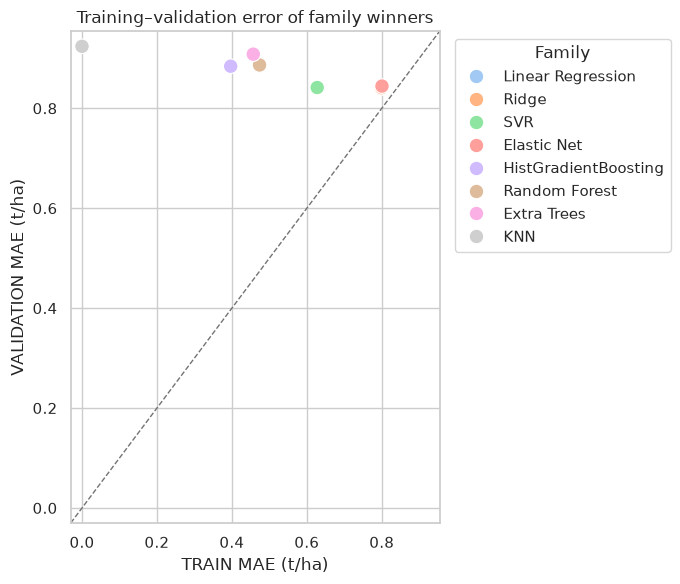

In [11]:
plt.figure(figsize=(7, 6))
sns.scatterplot(
    data=family_best,
    x="train_mae",
    y="val_mae",
    hue="family",
    s=110,
    palette="pastel",
)
limits = [
    min(family_best["train_mae"].min(), family_best["val_mae"].min()) - 0.03,
    max(family_best["train_mae"].max(), family_best["val_mae"].max()) + 0.03,
]
plt.plot(limits, limits, linestyle="--", linewidth=1, color="0.45")
plt.xlim(limits)
plt.ylim(limits)
plt.xlabel("TRAIN MAE (t/ha)")
plt.ylabel("VALIDATION MAE (t/ha)")
plt.title("Training–validation error of family winners")
plt.legend(title="Family", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(FIG_DIR / "04_train_validation_mae.png", dpi=160, bbox_inches="tight")
plt.show()

## Select the top three algorithm families

In [12]:
top3 = family_best.head(3).copy()
top3["selected_for_optimization"] = True
top3.to_csv(TABLE_DIR / "top3_algorithms.csv", index=False)

top3[
    [
        "family_rank",
        "family",
        "config_id",
        "params",
        "val_mae",
        "val_rmse",
        "val_r2",
        "mae_gap_val_minus_train",
    ]
]

,family_rank,family,config_id,params,val_mae,val_rmse,val_r2,mae_gap_val_minus_train
0,1,Linear Regression,linear_default,{},0.840810,1.060297,0.452110,0.041563
1,2,Ridge,ridge_alpha0.1,"{""alpha"": 0.1}",0.841264,1.060588,0.451808,0.042001
2,3,SVR,svr_rbf_C1,"{""C"": 1.0, ""epsilon"": 0.1, ""gamma"": ""scale"", ""...",0.841608,1.071350,0.440627,0.213924


In [13]:
top3_records = []
for _, row in top3.iterrows():
    top3_records.append(
        {
            "rank": int(row["family_rank"]),
            "family": row["family"],
            "screening_config_id": row["config_id"],
            "screening_params": json.loads(row["params"]),
            "validation_mae_t_ha": float(row["val_mae"]),
            "validation_rmse_t_ha": float(row["val_rmse"]),
            "validation_r2": float(row["val_r2"]),
            "validation_minus_train_mae_gap": float(row["mae_gap_val_minus_train"]),
        }
    )

selection_manifest = {
    "dataset": DATASET,
    "task_type": "regression",
    "screening_scope": "fixed TRAIN/VALIDATION holdout only",
    "test_used": False,
    "primary_metric": "MAE",
    "primary_metric_direction": "minimize",
    "selection_level": "algorithm family",
    "target_units": "t/ha",
    "n_candidate_configurations": int(len(results_df)),
    "n_nonbaseline_families": int(len(family_best)),
    "top3": top3_records,
    "next_step": (
        "Optimize these three families using TRAIN-only cross-validation. "
        "Combine each estimator with preparation_pipeline_template.joblib inside CV. "
        "Keep TEST protected."
    ),
}

with (TASK_DIR / "top3_selection_manifest.json").open("w", encoding="utf-8") as handle:
    json.dump(selection_manifest, handle, indent=2)

print(json.dumps(selection_manifest, indent=2))

{
  "dataset": "synthetic_crop_yield",
  "task_type": "regression",
  "screening_scope": "fixed TRAIN/VALIDATION holdout only",
  "test_used": false,
  "primary_metric": "MAE",
  "primary_metric_direction": "minimize",
  "selection_level": "algorithm family",
  "target_units": "t/ha",
  "n_candidate_configurations": 23,
  "n_nonbaseline_families": 8,
  "top3": [
    {
      "rank": 1,
      "family": "Linear Regression",
      "screening_config_id": "linear_default",
      "screening_params": {},
      "validation_mae_t_ha": 0.8408097516346721,
      "validation_rmse_t_ha": 1.0602965305265146,
      "validation_r2": 0.4521099550243751,
      "validation_minus_train_mae_gap": 0.04156325913821446
    },
    {
      "rank": 2,
      "family": "Ridge",
      "screening_config_id": "ridge_alpha0.1",
      "screening_params": {
        "alpha": 0.1
      },
      "validation_mae_t_ha": 0.8412638580169477,
      "validation_rmse_t_ha": 1.0605881959076402,
      "validation_r2": 0.451808487400

## Prediction and residual behavior of the selected families

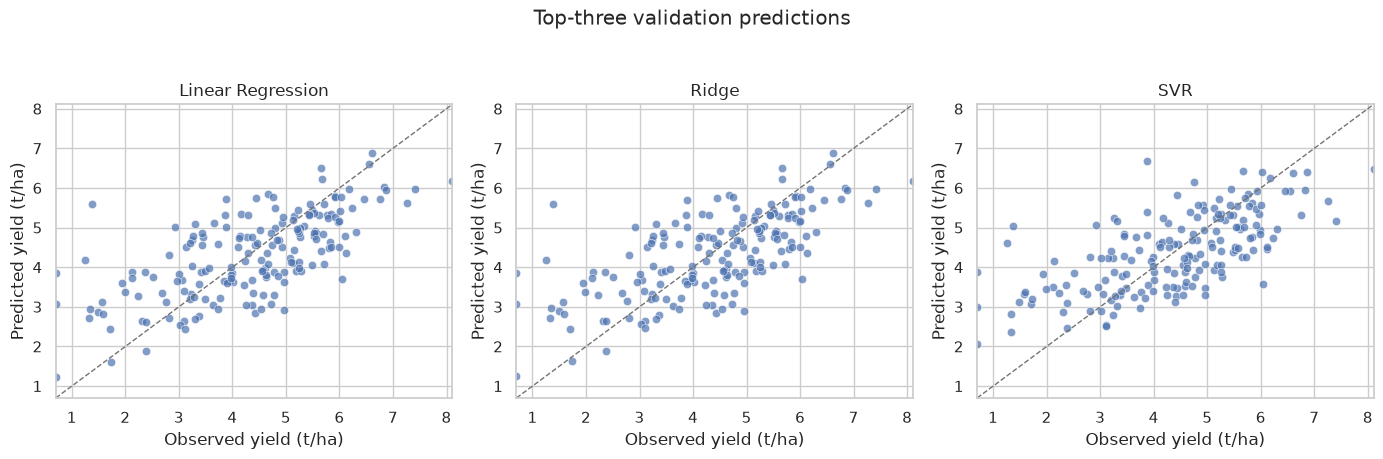

In [14]:
top3_models = {
    row["family"]: fitted_by_config[row["config_id"]]
    for _, row in top3.iterrows()
}

prediction_rows = []
for family, model in top3_models.items():
    pred = model.predict(X_val)
    for sample_id, observed, predicted in zip(val_df[ID_COL], y_val, pred):
        prediction_rows.append(
            {
                ID_COL: sample_id,
                "family": family,
                "observed": observed,
                "predicted": predicted,
                "residual": observed - predicted,
                "absolute_error": abs(observed - predicted),
            }
        )

prediction_df = pd.DataFrame(prediction_rows)
prediction_df.to_csv(TABLE_DIR / "top3_validation_predictions.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
global_min = min(prediction_df["observed"].min(), prediction_df["predicted"].min())
global_max = max(prediction_df["observed"].max(), prediction_df["predicted"].max())

for ax, family in zip(axes, top3_models):
    subset = prediction_df.loc[prediction_df["family"] == family]
    sns.scatterplot(data=subset, x="observed", y="predicted", alpha=0.7, ax=ax)
    ax.plot([global_min, global_max], [global_min, global_max], linestyle="--", color="0.45", linewidth=1)
    ax.set_title(family)
    ax.set_xlabel("Observed yield (t/ha)")
    ax.set_ylabel("Predicted yield (t/ha)")
    ax.set_xlim(global_min, global_max)
    ax.set_ylim(global_min, global_max)

fig.suptitle("Top-three validation predictions", y=1.04)
plt.tight_layout()
plt.savefig(FIG_DIR / "05_top3_observed_vs_predicted.png", dpi=160, bbox_inches="tight")
plt.show()

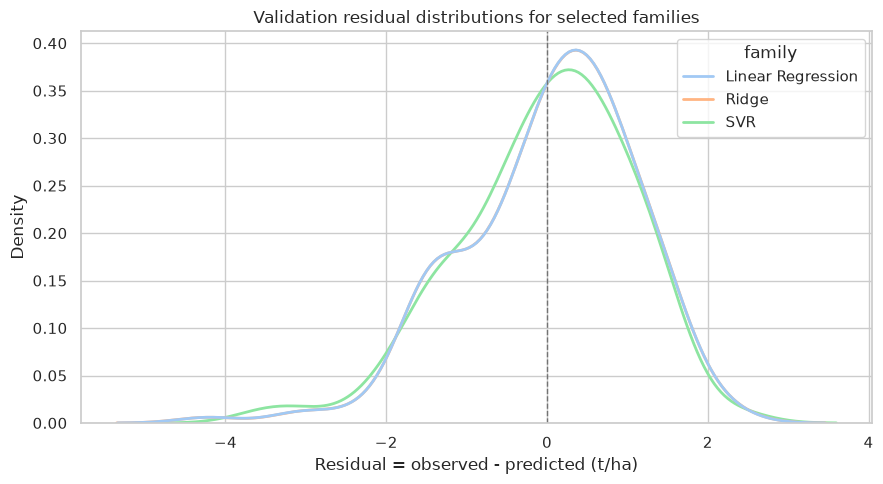

In [15]:
plt.figure(figsize=(9, 5))
sns.kdeplot(
    data=prediction_df,
    x="residual",
    hue="family",
    common_norm=False,
    fill=False,
    linewidth=2,
    palette="pastel",
)
plt.axvline(0, linestyle="--", color="0.45", linewidth=1)
plt.xlabel("Residual = observed - predicted (t/ha)")
plt.title("Validation residual distributions for selected families")
plt.tight_layout()
plt.savefig(FIG_DIR / "06_top3_residual_distributions.png", dpi=160, bbox_inches="tight")
plt.show()

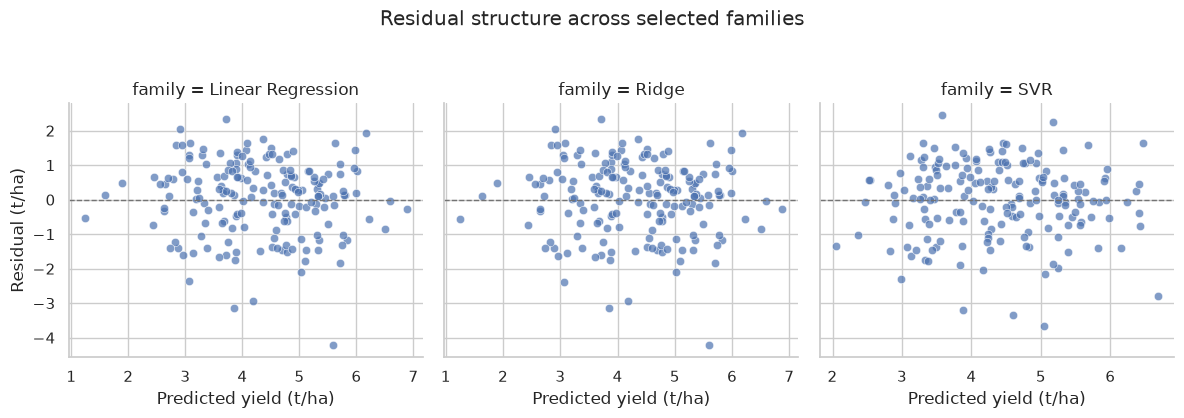

In [16]:
g = sns.relplot(
    data=prediction_df,
    x="predicted",
    y="residual",
    col="family",
    col_wrap=3,
    kind="scatter",
    alpha=0.7,
    height=4,
    facet_kws={"sharex": False, "sharey": True},
)
for ax in g.axes.flat:
    ax.axhline(0, linestyle="--", color="0.45", linewidth=1)
    ax.set_xlabel("Predicted yield (t/ha)")
    ax.set_ylabel("Residual (t/ha)")
g.fig.suptitle("Residual structure across selected families", y=1.04)
g.fig.tight_layout()
g.savefig(FIG_DIR / "07_top3_residual_vs_predicted.png", dpi=160, bbox_inches="tight")
plt.show()

## Interpretation and hand-off

The screening result identifies families worth spending optimization budget on. The current best
manual configuration is **not** treated as the final set of hyperparameters.

The next stage should:

1. read the top-three manifest;
2. define meaningful search spaces for those families;
3. combine each estimator with the unfitted preparation template;
4. optimize with cross-validation inside TRAIN;
5. compare optimized candidates under the predefined validation rule;
6. evaluate TEST only after the complete workflow is frozen.

In [17]:
print("Screening complete.")
print("Top three families:")
for record in top3_records:
    print(
        f"  {record['rank']}. {record['family']} "
        f"(validation MAE={record['validation_mae_t_ha']:.3f} t/ha)"
    )
print("\nTEST was not loaded or evaluated.")
print("Results:", TASK_DIR.relative_to(ROOT))

Screening complete.
Top three families:
  1. Linear Regression (validation MAE=0.841 t/ha)
  2. Ridge (validation MAE=0.841 t/ha)
  3. SVR (validation MAE=0.842 t/ha)

TEST was not loaded or evaluated.
Results: results/synthetic_crop_yield/model_screening
